# Subjectivity Mining, Assignment 5, Group 9
Ensemble methods for offensive language detection, in-domain and cross-domain

Group members: Ines Casado Vela, Martin Ranea Marina, Pablos Tselioudis Garmendia, Helian X. Liu

Content warning: this notebook shows offensive tweets from the datasets.

Same data and setup as Assignment 4. In-domain means training on olid-train-small.csv and testing on olid-test.csv. Cross-domain means training on hasoc-train.csv and testing on the same olid-test.csv. Labels: 0 = non-offensive, 1 = offensive.

| Part | Content | Done by | Folder |
|---|---|---|---|
| 1 | Common setup and hard majority voting | Ines Casado Vela | part1_ines_hard_voting |
| 2 | BERT probabilities and soft voting | Helian X. Liu | part2_helian_soft_voting |
| 3 | HateBERT probabilities, stacking, and all ensembles on the matched pool | Martin Ranea Marina | part3_martin_stacking |
| 4 | fBERT probabilities, Pearson correlations, error analysis and comparison | Pablos Tselioudis Garmendia | part4_pablos_analysis |

Notes:
- Parts 1 to 3 show the outputs from when each member ran their part. Each part first moves into its own folder, so it can be run again with its own files.
- Parts 1 and 2 use the base models of Assignment 4 (Part 2 with a retrained BERT). Part 3 builds all three ensembles on one shared set of base models, the matched pool. The final comparison in the report uses the matched pool.
- Training the transformers needs a GPU. Everything else runs on a CPU.
- The report is in report/A5-report-Group9.pdf.

# Part 1. Common setup and hard majority voting (Ines Casado Vela)

In [ ]:
import os
from pathlib import Path
FINAL_DIR = Path.cwd()
os.chdir(FINAL_DIR / 'part1_ines_hard_voting')

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

DATA = Path("a4_component_predictions.csv")
df = pd.read_csv(DATA)

assert len(df) == 860
assert df["labels"].isin([0,1]).all()
display(df.head())

,id,text,labels,bert_in,hatebert_in,fbert_in,bert_cross,hatebert_cross,fbert_cross,hard_in,hard_cross
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,1,1,1,1,1,1,1,1
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0,0,0,1,0,0,0,0
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0,0,0,0,0,0,0,0
3,13876,#Watching #Boomer getting the news that she is...,0,0,0,0,0,0,0,0,0
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0,0,0,0,0,0,0,0


## 1.1 Common evaluation function

The same evaluation function as in Assignment 4.

In [2]:
def evaluate_predictions(y_true, y_pred, model_name, setting, show_matrix=True):
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p, r, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0,1], zero_division=0
    )

    summary = pd.DataFrame([{
        "model": model_name,
        "setting": setting,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "precision_0": p[0], "recall_0": r[0], "f1_0": f1[0], "support_0": support[0],
        "precision_1": p[1], "recall_1": r[1], "f1_1": f1[1], "support_1": support[1],
    }])

    if show_matrix:
        cm = confusion_matrix(y_true, y_pred, labels=[0,1])
        disp = ConfusionMatrixDisplay(
            cm, display_labels=["Non-offensive (0)", "Offensive (1)"]
        )
        disp.plot(values_format="d")
        plt.title(f"{model_name} - {setting}")
        plt.tight_layout()
        plt.show()

    return summary

## 1.2 Checking the Assignment 4 predictions

The file has the test predictions of BERT, HateBERT and fBERT from Assignment 4, in both settings.

In [3]:
component_cols = [
    "bert_in", "hatebert_in", "fbert_in",
    "bert_cross", "hatebert_cross", "fbert_cross",
]
assert df[component_cols].isin([0,1]).all().all()

print("Rows:", len(df))
print("All three models agree, in-domain:",
      ((df.bert_in == df.hatebert_in) & (df.hatebert_in == df.fbert_in)).sum())
print("All three models agree, cross-domain:",
      ((df.bert_cross == df.hatebert_cross) & (df.hatebert_cross == df.fbert_cross)).sum())

Rows: 860
All three models agree, in-domain: 707
All three models agree, cross-domain: 647


## 1.3 Hard majority voting

The final label is the label predicted by at least two of the three models.

In [4]:
df["hard_in"] = (
    df[["bert_in", "hatebert_in", "fbert_in"]].sum(axis=1) >= 2
).astype(int)

df["hard_cross"] = (
    df[["bert_cross", "hatebert_cross", "fbert_cross"]].sum(axis=1) >= 2
).astype(int)

assert df["hard_in"].isin([0,1]).all()
assert df["hard_cross"].isin([0,1]).all()

display(df[[
    "id", "labels",
    "bert_in", "hatebert_in", "fbert_in", "hard_in",
    "bert_cross", "hatebert_cross", "fbert_cross", "hard_cross"
]].head(10))

,id,labels,bert_in,hatebert_in,fbert_in,hard_in,bert_cross,hatebert_cross,fbert_cross,hard_cross
0,15923,1,1,1,1,1,1,1,1,1
1,27014,0,0,0,0,0,1,0,0,0
2,30530,0,0,0,0,0,0,0,0,0
3,13876,0,0,0,0,0,0,0,0,0
4,60133,1,0,0,0,0,0,0,0,0
5,83681,1,1,1,1,1,1,1,1,1
6,96874,0,0,0,1,0,0,0,0,0
7,65507,1,0,0,1,0,1,1,1,1
8,78910,0,0,0,0,0,0,0,0,0
9,46363,0,0,0,0,0,0,0,0,0


## 1.4 In-domain results

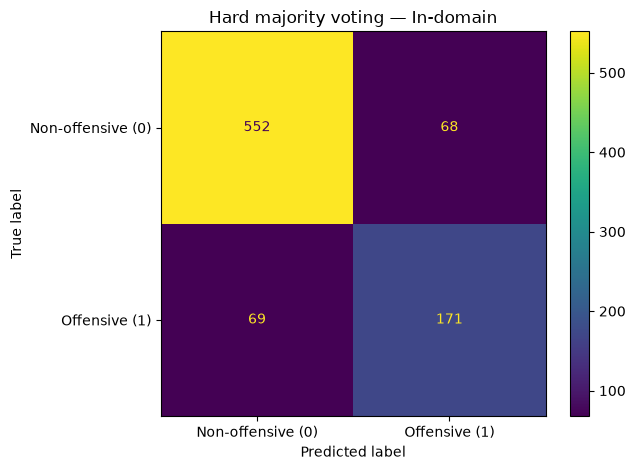

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Hard majority voting,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.714,240


In [5]:
metrics_in = evaluate_predictions(
    df.labels, df.hard_in,
    "Hard majority voting", "In-domain", show_matrix=True
)
display(metrics_in.round(4))

## 1.5 Cross-domain results

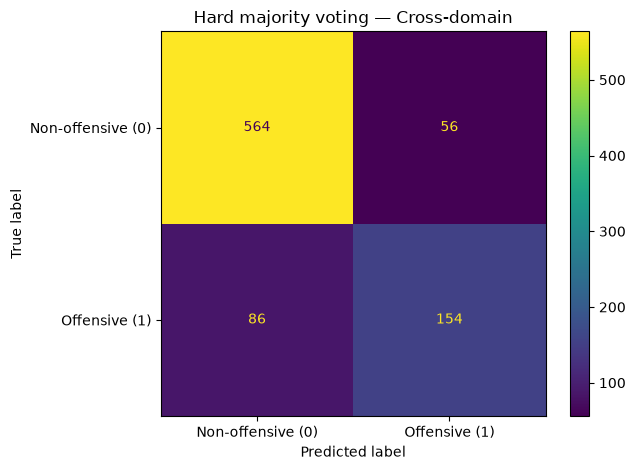

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Hard majority voting,Cross-domain,0.8349,0.8005,0.7757,0.7863,0.8677,0.9097,0.8882,620,0.7333,0.6417,0.6844,240


In [6]:
metrics_cross = evaluate_predictions(
    df.labels, df.hard_cross,
    "Hard majority voting", "Cross-domain", show_matrix=True
)
display(metrics_cross.round(4))

## 1.6 In-domain vs cross-domain

In [7]:
comparison = pd.concat([metrics_in, metrics_cross], ignore_index=True)
display(comparison.round(4))

f_in = float(metrics_in.loc[0, "macro_f1"])
f_cross = float(metrics_cross.loc[0, "macro_f1"])
drop = f_in - f_cross

print(f"In-domain macro-F1:     {f_in:.4f}")
print(f"Cross-domain macro-F1:  {f_cross:.4f}")
print(f"Absolute drop:          {drop:.4f}")
print(f"Relative drop:          {100*drop/f_in:.2f}%")

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Hard majority voting,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.7140,240
1,Hard majority voting,Cross-domain,0.8349,0.8005,0.7757,0.7863,0.8677,0.9097,0.8882,620,0.7333,0.6417,0.6844,240


In-domain macro-F1:     0.8018
Cross-domain macro-F1:  0.7863
Absolute drop:          0.0155
Relative drop:          1.93%


## 1.7 Comparison with fBERT, the best model of Assignment 4

In [8]:
# fBERT was the best individual model in Assignment 4.
fbert_macro_f1_in = 0.8033
fbert_macro_f1_cross = 0.8088

hard_in_f1 = float(metrics_in.loc[0, "macro_f1"])
hard_cross_f1 = float(metrics_cross.loc[0, "macro_f1"])

comparison_best = pd.DataFrame([
    {
        "setting": "In-domain",
        "fBERT_macro_f1": fbert_macro_f1_in,
        "hard_voting_macro_f1": hard_in_f1,
        "difference_hard_minus_fBERT": hard_in_f1 - fbert_macro_f1_in,
    },
    {
        "setting": "Cross-domain",
        "fBERT_macro_f1": fbert_macro_f1_cross,
        "hard_voting_macro_f1": hard_cross_f1,
        "difference_hard_minus_fBERT": hard_cross_f1 - fbert_macro_f1_cross,
    }
])
display(comparison_best.round(4))

,setting,fBERT_macro_f1,hard_voting_macro_f1,difference_hard_minus_fBERT
0,In-domain,0.8033,0.8018,-0.0015
1,Cross-domain,0.8088,0.7863,-0.0225


## 1.8 Interpretation

Hard voting does not beat fBERT. The three models agree on most tweets, and fBERT can be outvoted by the two weaker models.

## 1.9 Saving the results

In [9]:
out = Path(".")

res_in = df[["id","text","labels","bert_in","hatebert_in","fbert_in","hard_in"]].copy()
res_in = res_in.rename(columns={"hard_in":"prediction"})
res_in["correct"] = res_in.labels == res_in.prediction
res_in.to_csv(out / "results_hard_voting_in_domain.csv", index=False)

res_cross = df[["id","text","labels","bert_cross","hatebert_cross","fbert_cross","hard_cross"]].copy()
res_cross = res_cross.rename(columns={"hard_cross":"prediction"})
res_cross["correct"] = res_cross.labels == res_cross.prediction
res_cross.to_csv(out / "results_hard_voting_cross_domain.csv", index=False)

metrics_in.to_csv(out / "metrics_hard_voting_in_domain.csv", index=False)
metrics_cross.to_csv(out / "metrics_hard_voting_cross_domain.csv", index=False)
comparison.to_csv(out / "metrics_hard_voting_comparison.csv", index=False)

print("Saved all hard-voting result and metric files.")

Saved all hard-voting result and metric files.


# Part 2. BERT probabilities and soft voting (Helian X. Liu)

In [ ]:
os.chdir(FINAL_DIR / 'part2_helian_soft_voting')

## 2.1 Loading the probability files

BERT was retrained to get probabilities. HateBERT and fBERT probabilities come from the Assignment 4 models.

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
)


files = {
    "bert_in": "bert_probs_in_domain.csv",
    "bert_cross": "bert_probs_cross_domain.csv",
    "hatebert_in": "results_hatebert_in_domain.csv",
    "hatebert_cross": "results_hatebert_cross_domain.csv",
    "fbert_in": "results_fbert_in_domain.csv",
    "fbert_cross": "results_fbert_cross_domain.csv",
}
data = {}
for name, filename in files.items():
    path = Path(filename)
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.resolve()}")
    frame = pd.read_csv(path)
    needed = {"id", "text", "labels", "probability_offensive"}
    assert needed.issubset(frame.columns), f"Missing columns in {filename}: {needed - set(frame.columns)}"
    assert len(frame) == 860 and frame["id"].is_unique, f"Unexpected rows or duplicate IDs: {filename}"
    assert frame["labels"].isin([0, 1]).all(), filename
    assert frame["probability_offensive"].notna().all() and frame["probability_offensive"].between(0, 1).all(), filename
    data[name] = frame
    print(name, frame.shape)


bert_in (860, 5)
bert_cross (860, 5)
hatebert_in (860, 8)
hatebert_cross (860, 8)
fbert_in (860, 8)
fbert_cross (860, 8)


## 2.2 Common evaluation function

In [20]:
def evaluate_predictions(y_true, y_pred, model_name, setting, show_matrix=True):
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p, r, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    summary = pd.DataFrame([{
        "model": model_name, "setting": setting,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": macro_p, "macro_recall": macro_r, "macro_f1": macro_f1,
        "precision_0": p[0], "recall_0": r[0], "f1_0": f1[0], "support_0": support[0],
        "precision_1": p[1], "recall_1": r[1], "f1_1": f1[1], "support_1": support[1],
    }])
    if show_matrix:
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        disp = ConfusionMatrixDisplay(cm, display_labels=["Non-offensive (0)", "Offensive (1)"])
        disp.plot(values_format="d")
        plt.title(f"{model_name} - {setting}")
        plt.tight_layout()
        plt.show()
    return summary


## 2.3 Checking that the files line up

In [25]:
def align_predictions(suffix):
    columns = ["id", "text", "labels", "probability_offensive"]
    result = data[f"bert_{suffix}"][columns].rename(columns={"probability_offensive": "bert_prob"}).copy()
    for model in ("hatebert", "fbert"):
        other = data[f"{model}_{suffix}"][columns].rename(
            columns={"probability_offensive": f"{model}_prob"}
        )
        result = result.merge(other, on=["id", "text", "labels"], how="inner", validate="one_to_one")
    assert len(result) == 860, f"Sample mismatch in {suffix}: {len(result)} matched"
    return result

aligned_in = align_predictions("in")
aligned_cross = align_predictions("cross")
assert aligned_in[["id", "text", "labels"]].equals(aligned_cross[["id", "text", "labels"]])
print("Aligned in-domain:", aligned_in.shape)
print("Aligned cross-domain:", aligned_cross.shape)
display(aligned_in.head())


Aligned in-domain: (860, 6)
Aligned cross-domain: (860, 6)


,id,text,labels,bert_prob,hatebert_prob,fbert_prob
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,0.259567,0.886862,0.947962
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0.902438,0.108708,0.090735
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0.028571,0.116312,0.106505
3,13876,#Watching #Boomer getting the news that she is...,0,0.007681,0.012674,0.004682
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0.225118,0.016689,0.017849


## 2.4 Soft voting

The offensive probabilities of the three models are averaged. The tweet is predicted offensive when the average is at least 0.5.

In [29]:
def soft_voting(frame):
    result = frame.copy()
    result["probability_offensive"] = result[["bert_prob", "hatebert_prob", "fbert_prob"]].mean(axis=1)
    result["prediction"] = (result["probability_offensive"] >= 0.5).astype(int)
    result["correct"] = result["labels"] == result["prediction"]
    return result

soft_in = soft_voting(aligned_in)
soft_cross = soft_voting(aligned_cross)
print("In-domain predictions:\n", soft_in["prediction"].value_counts().sort_index())
print("Cross-domain predictions:\n", soft_cross["prediction"].value_counts().sort_index())
display(soft_in.head())


In-domain predictions:
 prediction
0    622
1    238
Name: count, dtype: int64
Cross-domain predictions:
 prediction
0    661
1    199
Name: count, dtype: int64


,id,text,labels,bert_prob,hatebert_prob,fbert_prob,probability_offensive,prediction,correct
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,0.259567,0.886862,0.947962,0.698131,1,True
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0.902438,0.108708,0.090735,0.367294,0,True
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0.028571,0.116312,0.106505,0.083796,0,True
3,13876,#Watching #Boomer getting the news that she is...,0,0.007681,0.012674,0.004682,0.008345,0,True
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0.225118,0.016689,0.017849,0.086552,0,False


## 2.5 In-domain results

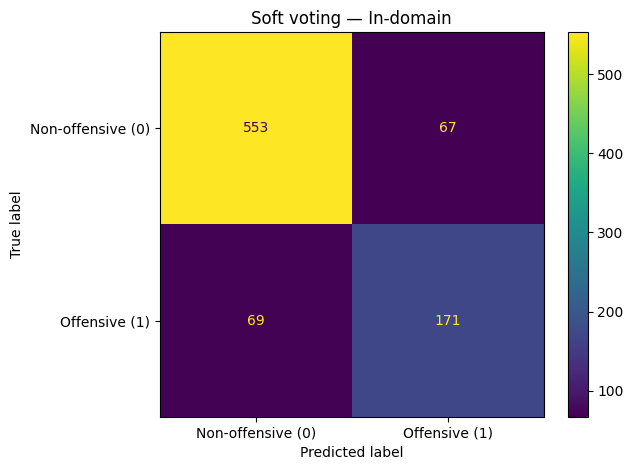

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Soft voting,In-domain,0.8419,0.8038,0.8022,0.803,0.8891,0.8919,0.8905,620,0.7185,0.7125,0.7155,240


In [34]:
metrics_in = evaluate_predictions(soft_in["labels"], soft_in["prediction"], "Soft voting", "In-domain")
display(metrics_in.round(4))

## 2.6 Cross-domain results

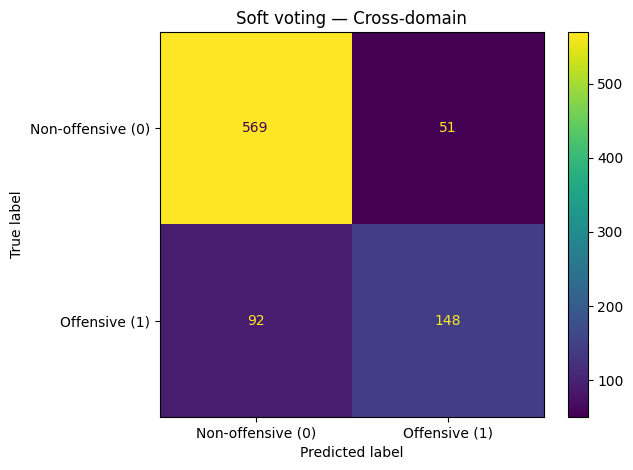

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Soft voting,Cross-domain,0.8337,0.8023,0.7672,0.7813,0.8608,0.9177,0.8884,620,0.7437,0.6167,0.6743,240


In [37]:
metrics_cross = evaluate_predictions(soft_cross["labels"], soft_cross["prediction"], "Soft voting", "Cross-domain")
display(metrics_cross.round(4))

## 2.7 In-domain vs cross-domain

In [42]:
comparison = pd.concat([metrics_in, metrics_cross], ignore_index=True)
display(comparison.round(4))
f_in = float(metrics_in.loc[0, "macro_f1"])
f_cross = float(metrics_cross.loc[0, "macro_f1"])
change = f_cross - f_in
print(f"In-domain macro-F1:     {f_in:.4f}")
print(f"Cross-domain macro-F1:  {f_cross:.4f}")
print(f"Cross minus in-domain:  {change:+.4f}")
print(f"Relative change:        {100 * change / f_in:+.2f}%")

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Soft voting,In-domain,0.8419,0.8038,0.8022,0.8030,0.8891,0.8919,0.8905,620,0.7185,0.7125,0.7155,240
1,Soft voting,Cross-domain,0.8337,0.8023,0.7672,0.7813,0.8608,0.9177,0.8884,620,0.7437,0.6167,0.6743,240


In-domain macro-F1:     0.8030
Cross-domain macro-F1:  0.7813
Cross minus in-domain:  -0.0217
Relative change:        -2.70%


## 2.8 Comparison with the single models

In [53]:
individual_rows = []
for suffix, setting in [("in", "In-domain"), ("cross", "Cross-domain")]:
    for model in ("bert", "hatebert", "fbert"):
        frame = data[f"{model}_{suffix}"]
        pred = (frame["probability_offensive"] >= 0.5).astype(int)
        score = evaluate_predictions(frame["labels"], pred, model, setting, show_matrix=False)
        individual_rows.append(score)
individual_metrics = pd.concat(individual_rows, ignore_index=True)
model_comparison = pd.concat([individual_metrics, comparison], ignore_index=True)
display(model_comparison[["model", "setting", "accuracy", "macro_precision", "macro_recall", "macro_f1"]].round(4))


,model,setting,accuracy,macro_precision,macro_recall,macro_f1
0,bert,In-domain,0.8233,0.7800,0.7842,0.7820
1,hatebert,In-domain,0.8407,0.8022,0.8014,0.8018
2,fbert,In-domain,0.8407,0.8014,0.8052,0.8033
3,bert,Cross-domain,0.7802,0.7264,0.7186,0.7222
4,hatebert,Cross-domain,0.8035,0.7560,0.7513,0.7536
5,fbert,Cross-domain,0.8547,0.8317,0.7932,0.8088
6,Soft voting,In-domain,0.8419,0.8038,0.8022,0.8030
7,Soft voting,Cross-domain,0.8337,0.8023,0.7672,0.7813


## 2.9 Interpretation

Soft voting is close to fBERT in-domain but stays below it cross-domain, since all three models get the same weight.

## 2.10 Saving the results and confusion matrices

In [56]:
out = Path(".")
soft_in.to_csv(out / "results_soft_voting_in_domain.csv", index=False)
soft_cross.to_csv(out / "results_soft_voting_cross_domain.csv", index=False)
metrics_in.to_csv(out / "metrics_soft_voting_in_domain.csv", index=False)
metrics_cross.to_csv(out / "metrics_soft_voting_cross_domain.csv", index=False)
comparison.to_csv(out / "metrics_soft_voting_comparison.csv", index=False)
model_comparison.to_csv(out / "metrics_soft_voting_vs_individual.csv", index=False)
print("Saved soft-voting results and metric CSV files.")

Saved soft-voting results and metric CSV files.


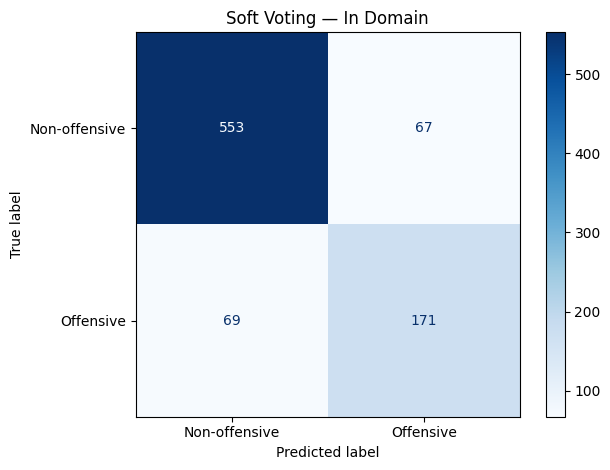

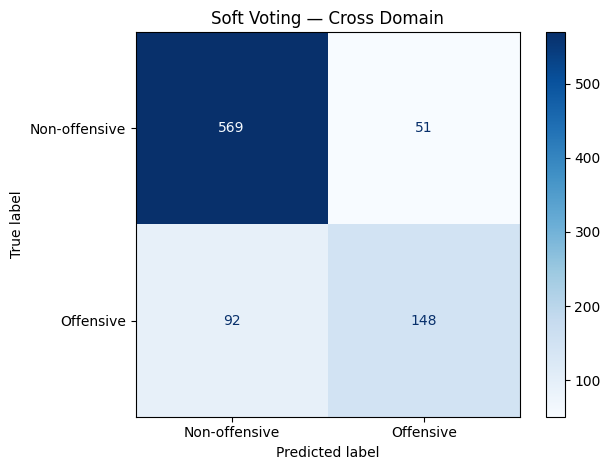

Confusion matrix images saved.


In [58]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create output folder
pics = Path("pics")
pics.mkdir(exist_ok=True)

for name, df in [
    ("in_domain", soft_in),
    ("cross_domain", soft_cross)
]:
    cm = confusion_matrix(
        df["labels"],
        df["prediction"],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-offensive", "Offensive"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Soft Voting - {name.replace('_', ' ').title()}")
    plt.tight_layout()

    plt.savefig(
        pics / f"confusion_soft_voting_{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Confusion matrix images saved.")

# Part 3. HateBERT probabilities and stacking (Martin Ranea Marina)

In [ ]:
os.chdir(FINAL_DIR / 'part3_martin_stacking')

## 3.1 Setup

The scripts in this folder train the base models (a5_stacking.py) and fit the stacking meta-models from the saved out-of-fold features (evaluate_stacking.py). Reading the saved results needs no GPU.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
from a5_stacking import MODELS, PARAMS, PROB_COLUMNS, EXTRA_COLUMNS, text_features, load_data
from shared_evaluation import evaluate_predictions
ROOT = Path('.')
OUT = ROOT / 'stacking_results'
data = load_data(ROOT)
protocol = json.loads((OUT / 'prespecified_protocol.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model': name, 'checkpoint': value[0], 'revision': value[1]} for name,value in MODELS.items()]))


,model,checkpoint,revision
0,bert,google-bert/bert-base-uncased,86b5e0934494bd15c9632b12f734a8a67f723594
1,hatebert,GroNLP/hateBERT,ab7a2d40f6c973cb57e63f23bfa2b51d981d028c
2,fbert,diptanu/fBERT,c089daa35cb177238dd91ffe3010c2d8bbd069bf


## 3.2 Data and folds

Both training sets are split into three folds with StratifiedGroupKFold. Identical texts stay in the same fold.

In [2]:
display(pd.read_csv(OUT / 'dataset_audit.csv'))
for setting in ['in_domain','cross_domain']:
    membership = pd.read_csv(OUT / f'folds_{setting}.csv')
    print(setting)
    display(membership.groupby('fold').labels.agg(n='size', offensive='sum'))


,dataset,rows,class_0,class_1,duplicate_text_rows,matching_test_texts
0,olid-train-small.csv,5852,3591,2261,8,3
1,hasoc-train.csv,5852,3591,2261,78,0


in_domain


,n,offensive
fold,,
0,1953,766
1,1948,747
2,1951,748


cross_domain


,n,offensive
fold,,
0,1944,761
1,1949,752
2,1959,748


## 3.3 HateBERT probabilities

The saved HateBERT models from Assignment 4 were loaded again, and their probabilities match the ones used in Part 2.

In [3]:
for setting in ['in_domain','cross_domain']:
    ours = pd.read_csv(f'hatebert_probs_{setting}.csv')
    shared = pd.read_csv(f'provided/helian/results_soft_voting_{setting}.csv')
    assert ours[['id','text','labels']].equals(shared[['id','text','labels']])
    np.testing.assert_allclose(ours.probability_offensive, shared.hatebert_prob, atol=1e-7, rtol=0)
    assert ours.probability_offensive.between(0,1).all()
    np.testing.assert_allclose(ours.probability_offensive + ours.probability_non_offensive, 1)
    display(evaluate_predictions(ours.labels, ours.prediction, 'HateBERT', setting.replace('_','-').capitalize(), show_matrix=False).round(4))
print('HateBERT probability exports are verified.')


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.714,240


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,Cross-domain,0.8035,0.756,0.7513,0.7536,0.8596,0.8694,0.8645,620,0.6524,0.6333,0.6427,240


HateBERT probability exports are verified.


## 3.4 Training settings and extra features

Every new base model uses the same settings as HateBERT in Assignment 4. The meta-model gets the three probabilities and six text features.

In [4]:
display(pd.DataFrame([PARAMS]).T.rename(columns={0:'value'}))
print('Probability columns:', PROB_COLUMNS)
print('Additional columns:', EXTRA_COLUMNS)
display(text_features(data['olid-test.csv'].text.head(5)))


,value
num_train_epochs,3
learning_rate,0.00002
train_batch_size,8
gradient_accumulation_steps,2
eval_batch_size,32
max_seq_length,128
optimizer,AdamW
scheduler,linear_schedule_with_warmup
warmup_ratio,0.06
warmup_steps,0


Probability columns: ['bert_prob', 'hatebert_prob', 'fbert_prob']
Additional columns: ['log_characters', 'log_words', 'uppercase_fraction', 'exclamation_count', 'question_count', 'hashtag_count']


,log_characters,log_words,uppercase_fraction,exclamation_count,question_count,hashtag_count
0,5.505332,3.332205,0.302564,3,0,7
1,4.718499,2.639057,0.063830,0,0,1
2,5.323010,3.367296,0.496599,0,0,14
3,4.941642,3.178054,0.101852,0,0,3
4,4.595120,2.890372,0.140845,1,0,4


## 3.5 Fitting the meta-models

The meta-models are fitted again from the saved out-of-fold probabilities, and the saved results are checked.

In [5]:
from evaluate_stacking import evaluate
all_metrics = evaluate(ROOT)
from verify_delivery import verify
verification = verify(ROOT, reload_base_models=False)
print('Verification status:', verification['status'])


   model      setting  accuracy  macro_precision  macro_recall  macro_f1  precision_0  recall_0     f1_0  support_0  precision_1  recall_1     f1_1  support_1
Stacking    In-domain  0.855814         0.823396      0.813172  0.818001     0.892405  0.909677 0.900958        620     0.754386  0.716667 0.735043        240
Stacking Cross-domain  0.851163         0.830951      0.783132  0.801550     0.867164  0.937097 0.900775        620     0.794737  0.629167 0.702326        240


Verified OOF provenance, fixed test rows, supplied metrics and saved meta-model reloads.


Delivery verification passed.


Verification status: passed


## 3.6 Stacking results

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Stacking,In-domain,0.8558,0.8234,0.8132,0.8180,0.8924,0.9097,0.9010,620,0.7544,0.7167,0.7350,240
1,Stacking,Cross-domain,0.8512,0.8310,0.7831,0.8016,0.8672,0.9371,0.9008,620,0.7947,0.6292,0.7023,240


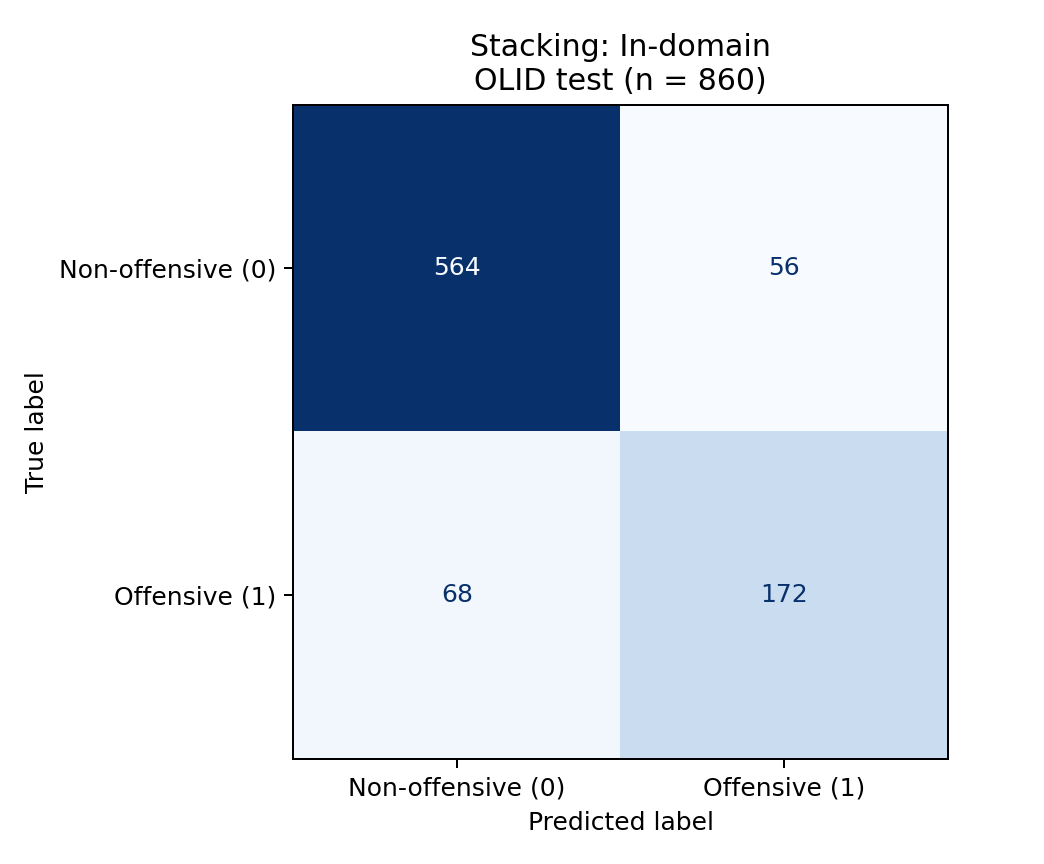

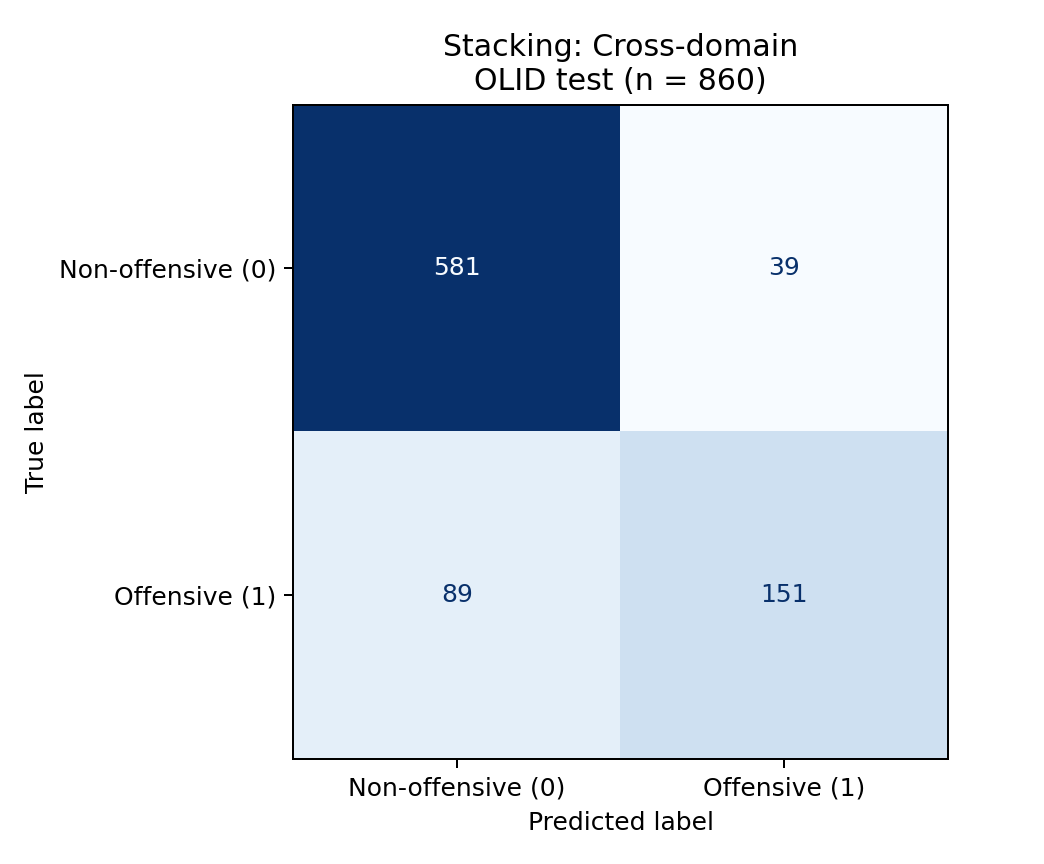

,model,macro_f1_in_domain,macro_f1_cross_domain,absolute_drop,percentage_point_drop,relative_drop_percent
0,Stacking,0.818,0.8016,0.0165,1.645,2.011


In [6]:
stacking = pd.read_csv(OUT / 'metrics_stacking_comparison.csv')
display(stacking.round(4))
for setting in ['in_domain','cross_domain']:
    display(Image(filename=str(OUT / f'confusion_stacking_{setting}.png')))
changes = pd.read_csv(OUT / 'domain_changes.csv')
display(changes[changes.model == 'Stacking'].round(4))


## 3.7 All ensembles on the matched pool

Parts 1 and 2 used slightly different BERT models, so here all three ensembles are built from the same base models.

,model,setting,macro_precision,macro_recall,macro_f1
0,Stacking,In-domain,0.8234,0.8132,0.8180
1,Stacking (probabilities only),In-domain,0.8209,0.8090,0.8146
2,bert,In-domain,0.8002,0.7947,0.7973
3,hatebert,In-domain,0.8022,0.8014,0.8018
4,fbert,In-domain,0.8136,0.8071,0.8102
5,Hard voting (matched),In-domain,0.8103,0.8054,0.8078
6,Soft voting (matched),In-domain,0.8276,0.8181,0.8226
7,Stacking,Cross-domain,0.8310,0.7831,0.8016
8,Stacking (probabilities only),Cross-domain,0.8341,0.7793,0.7997
9,bert,Cross-domain,0.7648,0.7274,0.7415


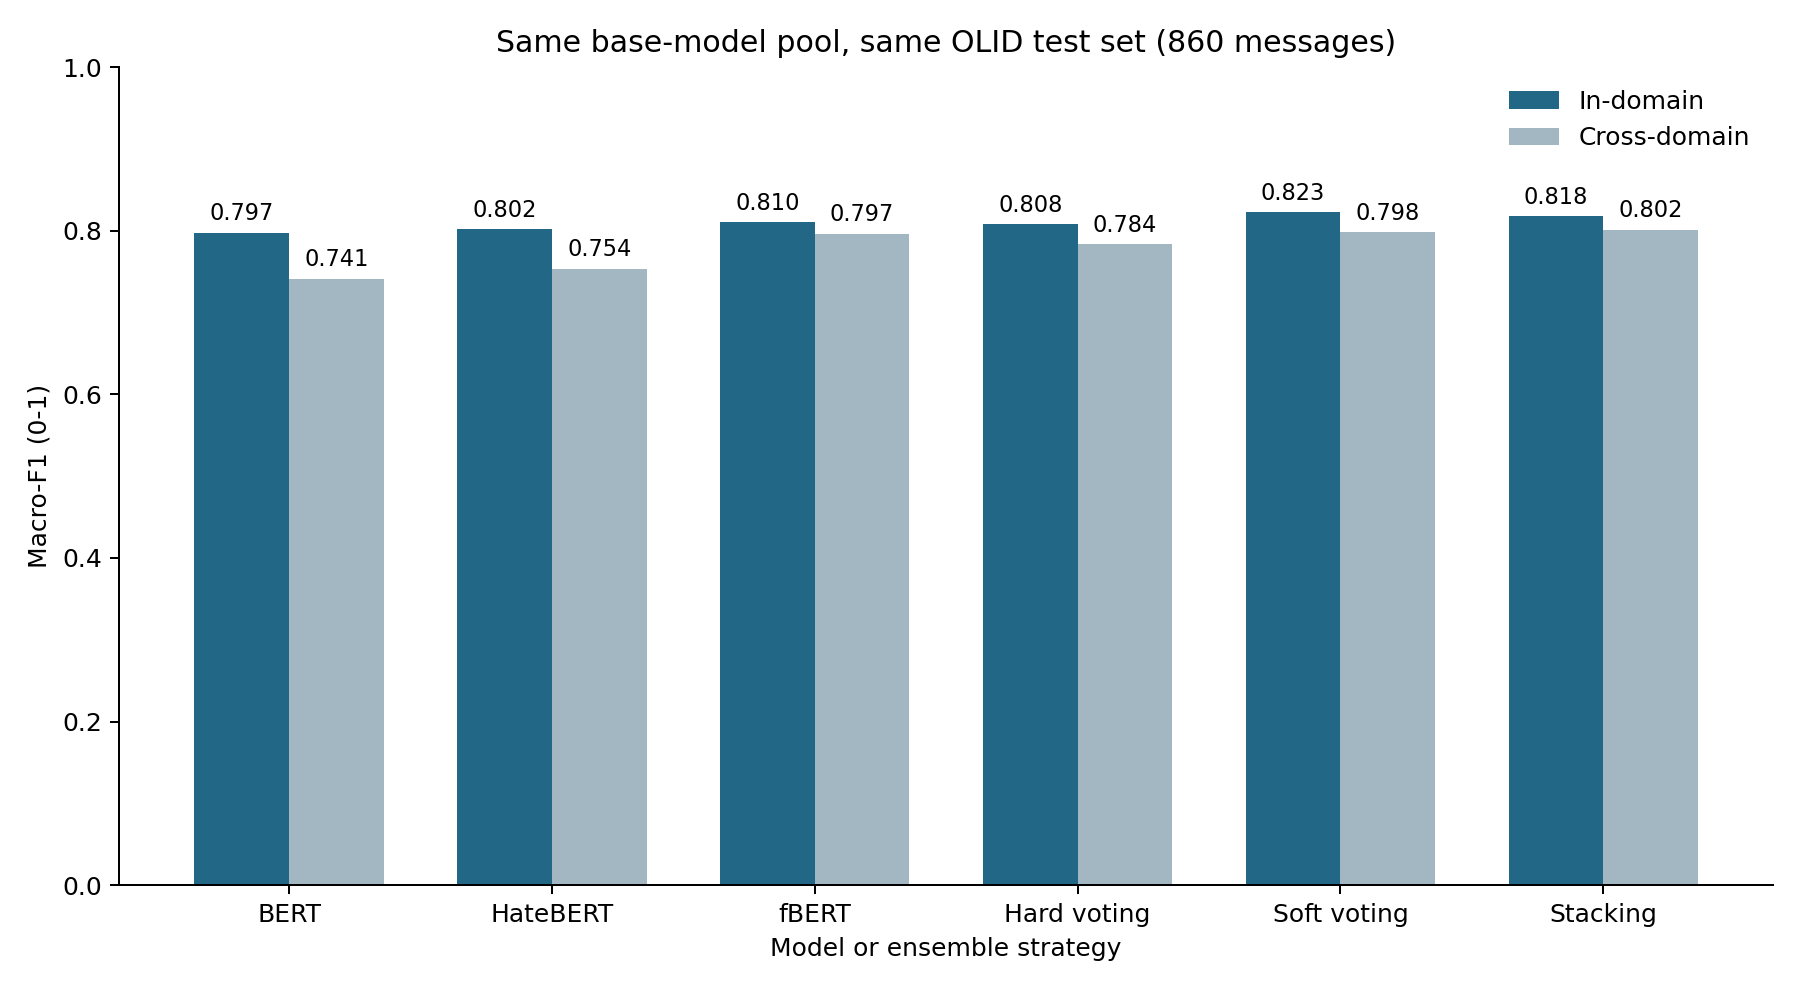

,model,setting,pool,macro_f1
7,Hard voting (Ines),In-domain,Provided A4 labels,0.8018
8,Soft voting (Helian),In-domain,Provided Helian probabilities,0.8030
9,Stacking (shared-pool sensitivity),In-domain,Shared pool; base-fit mismatch,0.8121
17,Hard voting (Ines),Cross-domain,Provided A4 labels,0.7863
18,Soft voting (Helian),Cross-domain,Provided Helian probabilities,0.7813
19,Stacking (shared-pool sensitivity),Cross-domain,Shared pool; base-fit mismatch,0.7928


In [7]:
matched = pd.read_csv(OUT / 'metrics_matched_pool_comparison.csv')
display(matched[['model','setting','macro_precision','macro_recall','macro_f1']].round(4))
display(Image(filename=str(OUT / 'matched_model_comparison.png')))
display(all_metrics[all_metrics.pool != 'Matched A5'][['model','setting','pool','macro_f1']].round(4))


## 3.8 Effect of the extra features

Stacking with only the three probabilities, and the meta-model coefficients.

In [8]:
display(matched[matched.model.str.startswith('Stacking')][['model','setting','macro_f1']].round(4))
display(pd.read_csv(OUT / 'meta_coefficients.csv').round(4))


,model,setting,macro_f1
0,Stacking,In-domain,0.8180
1,Stacking (probabilities only),In-domain,0.8146
7,Stacking,Cross-domain,0.8016
8,Stacking (probabilities only),Cross-domain,0.7997


,setting,feature,standardized_coefficient
0,In-domain,bert_prob,0.1398
1,In-domain,hatebert_prob,0.1913
2,In-domain,fbert_prob,1.3579
3,In-domain,log_characters,-0.3121
4,In-domain,log_words,0.2956
5,In-domain,uppercase_fraction,-0.0670
6,In-domain,exclamation_count,0.0105
7,In-domain,question_count,0.1033
8,In-domain,hashtag_count,0.0043
9,Cross-domain,bert_prob,0.3194


## 3.9 Stacking errors

Error counts and all cross-domain errors, used in Part 4 for the manual analysis.

In [9]:
display(pd.read_csv(OUT / 'error_summary_stacking.csv').round(4))
display(pd.read_csv(OUT / 'errors_by_length_stacking.csv').round(4))
sample = pd.read_csv(OUT / 'cross_domain_review_sample.csv')
display(sample[['id','labels','prediction','error_type','text']])


,setting,TN,FP,FN,TP,false_positive_rate,false_negative_rate
0,In-domain,564,56,68,172,0.0903,0.2833
1,Cross-domain,581,39,89,151,0.0629,0.3708


,setting,length_group,n,offensive_support,errors,error_rate
0,In-domain,0-15 words,275,89,39,0.1418
1,In-domain,16-30 words,305,86,42,0.1377
2,In-domain,31+ words,280,65,43,0.1536
3,Cross-domain,0-15 words,275,89,34,0.1236
4,Cross-domain,16-30 words,305,86,50,0.1639
5,Cross-domain,31+ words,280,65,44,0.1571


,id,labels,prediction,error_type,text
0,15815,1,0,false_negative,#BelieveAllWomen just when I think things can'...
1,22594,1,0,false_negative,@USER @USER @USER Fascism was also against lib...
2,47445,1,0,false_negative,". JEFF SESSIONS: ‘LISTEN TO THE ACLU, ANTIFA, ..."
3,52445,1,0,false_negative,#Elitist #Actors #NBC #Liberals of #Dems in #H...
4,58026,1,0,false_negative,#MAGA #Qanon #GreatAwakening #inners #WWG1WGA ...
5,60133,1,0,false_negative,#NoPasaran: Unity demo to oppose the far-right...
6,62689,1,0,false_negative,#scottgimple ruined #TheWalkingDead and now he...
7,72531,1,0,false_negative,#GoodMorningAmerica #TuesdayMotivation #Thank...
8,80397,1,0,false_negative,#Liberals Are Reaching Peak Desperation To Cal...
9,83466,1,0,false_negative,#Beeto Just Demonstrated How To Lose An Electi...


# Part 4. fBERT probabilities, correlations and error analysis (Pablos Tselioudis Garmendia)

pablos_analysis.py does the whole analysis. It exports the fBERT probabilities of the Assignment 4 models, computes the Pearson correlations between the base models, compares every ensemble with fBERT using McNemar tests and breaks down the stacking errors. All comparisons use the matched pool from Part 3. annotate_errors.py holds the manual category of every cross-domain stacking error.

In [2]:
import sys
import pandas as pd
from IPython.display import display, Image

os.chdir(FINAL_DIR / 'part4_pablos_analysis')
sys.path.insert(0, str(Path.cwd()))
import annotate_errors
import pablos_analysis

annotate_errors.ann.to_csv('error_annotations_check.csv', index=False)
pablos_analysis.main()

== pearson_correlations
     setting             pair  r_probabilities  r_labels  r_errors  label_agreement
   In-domain  BERT / HateBERT           0.8313    0.7257    0.5943           0.8907
   In-domain     BERT / fBERT           0.8916    0.8143    0.7230           0.9267
   In-domain HateBERT / fBERT           0.8698    0.7809    0.6678           0.9128
Cross-domain  BERT / HateBERT           0.7648    0.6247    0.5488           0.8581
Cross-domain     BERT / fBERT           0.8116    0.6821    0.6124           0.8860
Cross-domain HateBERT / fBERT           0.7724    0.6306    0.5186           0.8581
== base_model_agreement
     setting  all_three_agree  all_three_correct  all_three_wrong  at_least_one_correct
   In-domain              744                665               79                   781
Cross-domain              689                610               79                   781
== mcnemar_ensembles_vs_fbert
     setting    system_a    system_b  only_a_correct  only_b_correct  

## 4.1 fBERT probabilities

The probabilities of the Assignment 4 fBERT models, in both settings. Part 2 used these.

In [3]:
display(pd.read_csv('results/fbert_probs_cross_domain.csv').head())

,id,text,labels,prediction,probability_offensive,probability_non_offensive
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,1,0.780579,0.219421
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0,0.130673,0.869327
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0,0.045226,0.954774
3,13876,#Watching #Boomer getting the news that she is...,0,0,0.072505,0.927495
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0,0.106180,0.893820


## 4.2 All systems on the matched pool

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,f1_0,f1_1
0,Stacking,In-domain,0.8558,0.8234,0.8132,0.8180,0.9010,0.7350
2,bert,In-domain,0.8384,0.8002,0.7947,0.7973,0.8885,0.7061
3,hatebert,In-domain,0.8407,0.8022,0.8014,0.8018,0.8896,0.7140
4,fbert,In-domain,0.8488,0.8136,0.8071,0.8102,0.8958,0.7246
5,Hard voting (matched),In-domain,0.8465,0.8103,0.8054,0.8078,0.8941,0.7215
6,Soft voting (matched),In-domain,0.8593,0.8276,0.8181,0.8226,0.9033,0.7420
7,Stacking,Cross-domain,0.8512,0.8310,0.7831,0.8016,0.9008,0.7023
9,bert,Cross-domain,0.8058,0.7648,0.7274,0.7415,0.8704,0.6125
10,hatebert,Cross-domain,0.8035,0.7560,0.7513,0.7536,0.8645,0.6427
11,fbert,Cross-domain,0.8430,0.8119,0.7851,0.7966,0.8938,0.6993


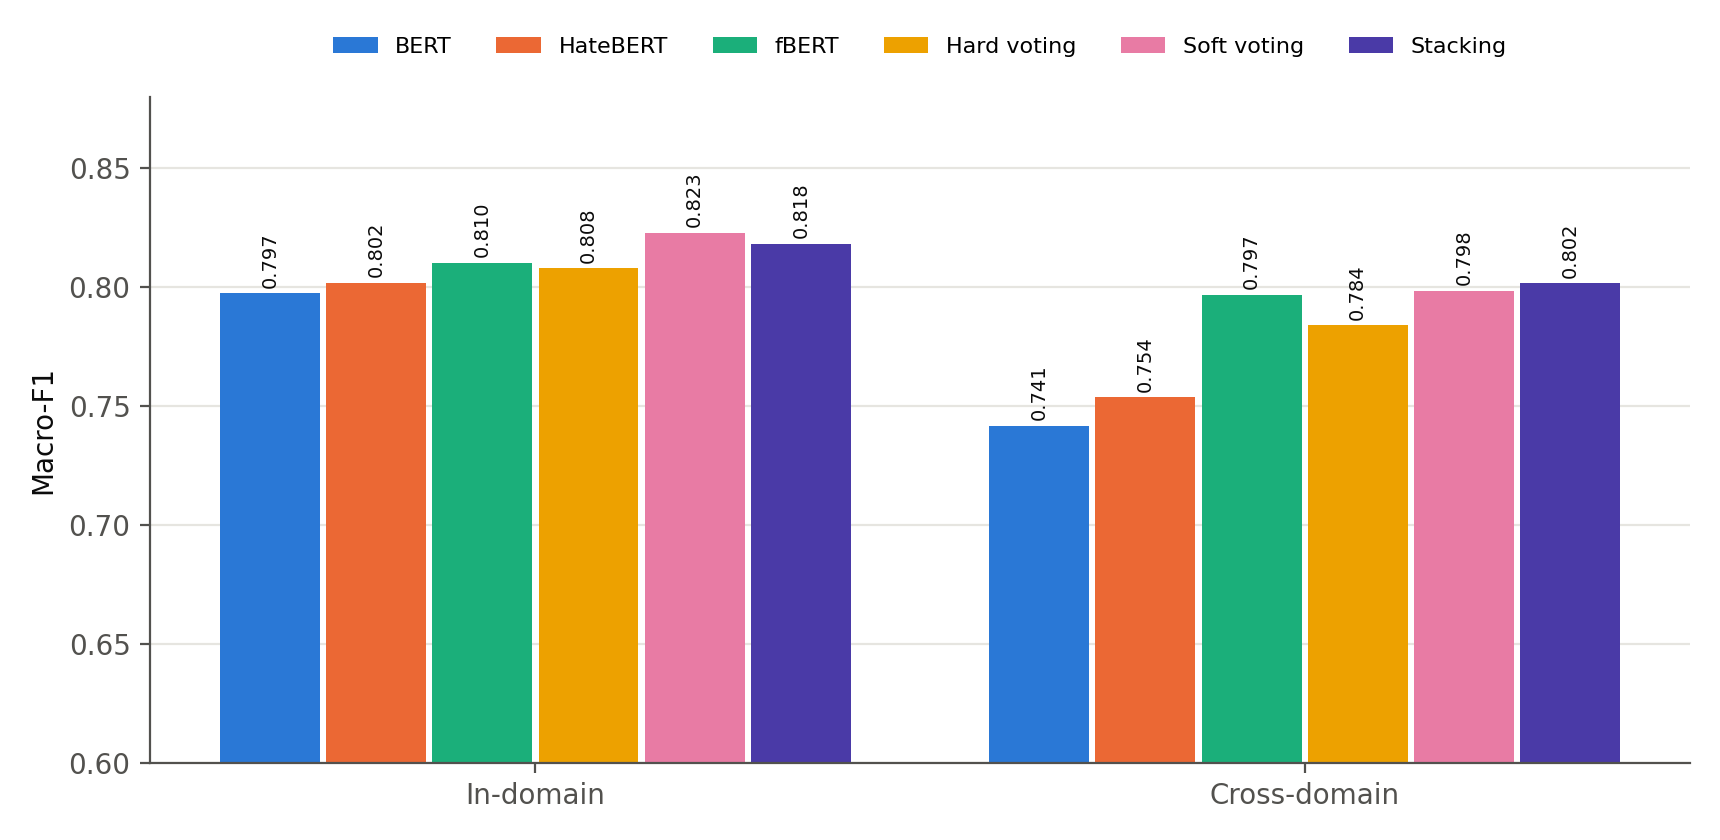

In [4]:
m = pd.read_csv(FINAL_DIR / 'part3_martin_stacking/stacking_results/metrics_matched_pool_comparison.csv')
m = m[~m.model.str.contains('probabilities only')]
display(m[['model', 'setting', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'f1_0', 'f1_1']].round(4))
display(Image(filename='pics/macro_f1_ensembles.png', width=750))

## 4.3 Pearson correlations between the base models

Correlations of the offensive probabilities, of the predicted labels and of the errors (1 when the model is wrong).

,setting,pair,r_probabilities,r_labels,r_errors,label_agreement
0,In-domain,BERT / HateBERT,0.831,0.726,0.594,0.891
1,In-domain,BERT / fBERT,0.892,0.814,0.723,0.927
2,In-domain,HateBERT / fBERT,0.870,0.781,0.668,0.913
3,Cross-domain,BERT / HateBERT,0.765,0.625,0.549,0.858
4,Cross-domain,BERT / fBERT,0.812,0.682,0.612,0.886
5,Cross-domain,HateBERT / fBERT,0.772,0.631,0.519,0.858


,setting,all_three_agree,all_three_correct,all_three_wrong,at_least_one_correct
0,In-domain,744,665,79,781
1,Cross-domain,689,610,79,781


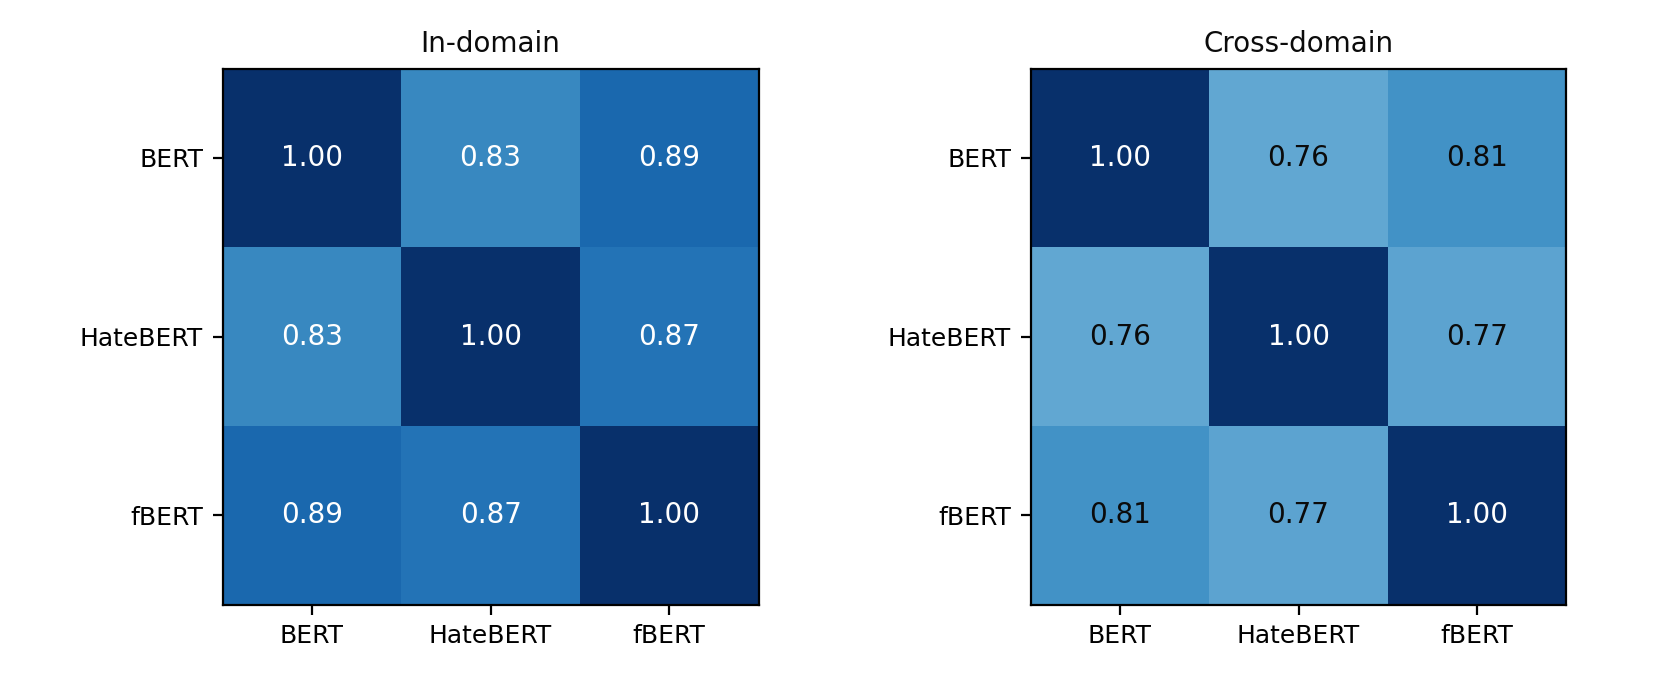

In [5]:
display(pd.read_csv('results/pearson_correlations.csv').round(3))
display(pd.read_csv('results/base_model_agreement.csv'))
display(Image(filename='pics/pearson_probabilities.png', width=650))

## 4.4 Ensembles against fBERT

Exact McNemar tests on the same 860 test tweets.

In [6]:
display(pd.read_csv('results/mcnemar_ensembles_vs_fbert.csv').round(4))

,setting,system_a,system_b,only_a_correct,only_b_correct,mcnemar_exact_p
0,In-domain,Stacking,fBERT,6,0,0.0312
1,In-domain,Soft voting,fBERT,21,12,0.1628
2,In-domain,Hard voting,fBERT,10,12,0.8318
3,In-domain,Stacking,Soft voting,13,16,0.7111
4,Cross-domain,Stacking,fBERT,23,16,0.3368
5,Cross-domain,Soft voting,fBERT,24,21,0.7660
6,Cross-domain,Hard voting,fBERT,21,28,0.3916
7,Cross-domain,Stacking,Soft voting,8,4,0.3877


## 4.5 Errors of stacking, the best ensemble

Confusion matrices, error rates by message length and the share of offensive tweets that are missed, with and without a swear word.

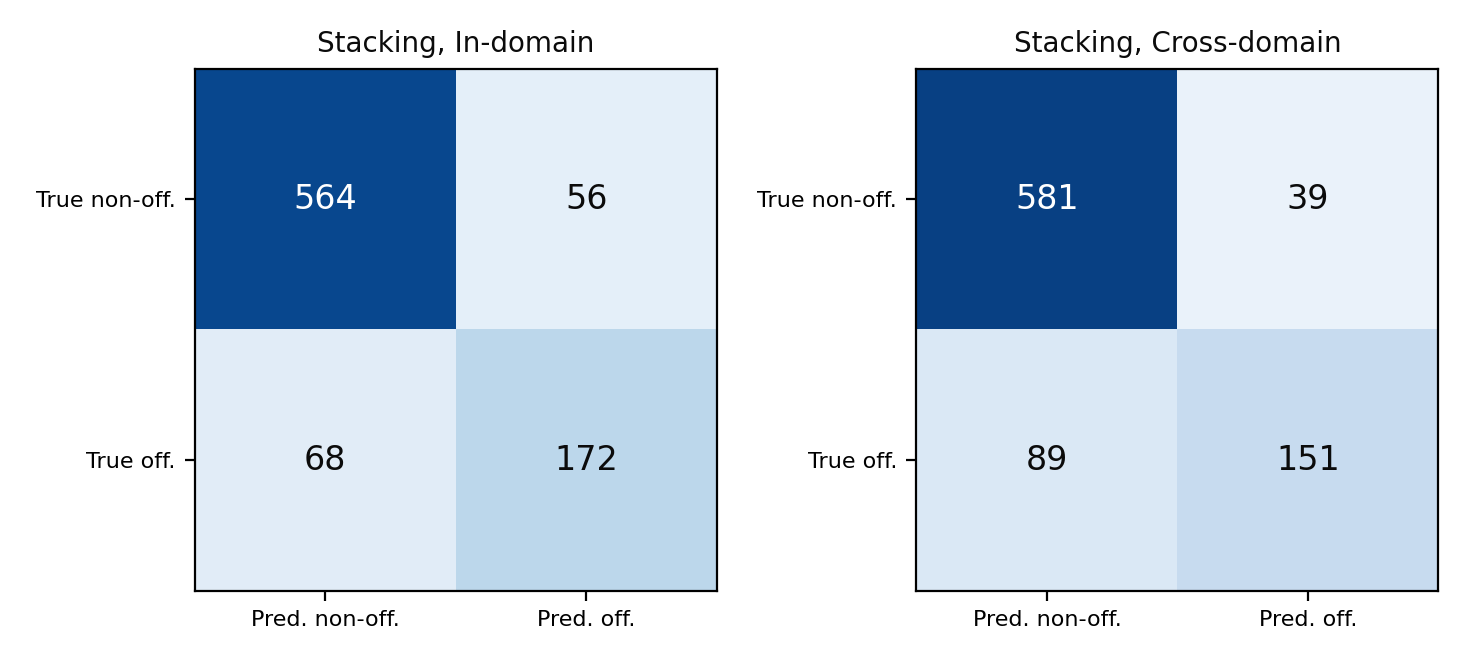

,setting,group,n,error_rate
0,In-domain,0-15 words,275,0.1418
1,In-domain,16-30 words,305,0.1377
2,In-domain,31+ words,280,0.1536
3,In-domain,"offensive, with swear word",88,0.0000
4,In-domain,"offensive, without swear word",152,0.4474
5,Cross-domain,0-15 words,275,0.1236
6,Cross-domain,16-30 words,305,0.1639
7,Cross-domain,31+ words,280,0.1571
8,Cross-domain,"offensive, with swear word",88,0.0568
9,Cross-domain,"offensive, without swear word",152,0.5526


In [7]:
display(Image(filename='pics/confusion_stacking.png', width=600))
display(pd.read_csv('results/stacking_error_breakdown.csv').round(4))

## 4.6 Manual analysis of the cross-domain errors

All 39 false positives and 89 false negatives of stacking in the cross-domain setting were read and given one main category, based on van Aken et al. (2018).

,error_type,category,n,percent_of_type
0,false_negative,Attack on a group or generalisation,24,27.0
1,false_negative,Doubtful gold label,26,29.2
2,false_negative,Implicit insult without swear words,12,13.5
3,false_negative,Offence only in hashtags,10,11.2
4,false_negative,"Sarcasm, irony, rhetorical question or metaphor",12,13.5
5,false_negative,Swear word or slur missed,5,5.6
6,false_positive,Doubtful gold label,7,17.9
7,false_positive,Identity or violence terms,9,23.1
8,false_positive,No clear cue,1,2.6
9,false_positive,Quotation or reported speech,2,5.1


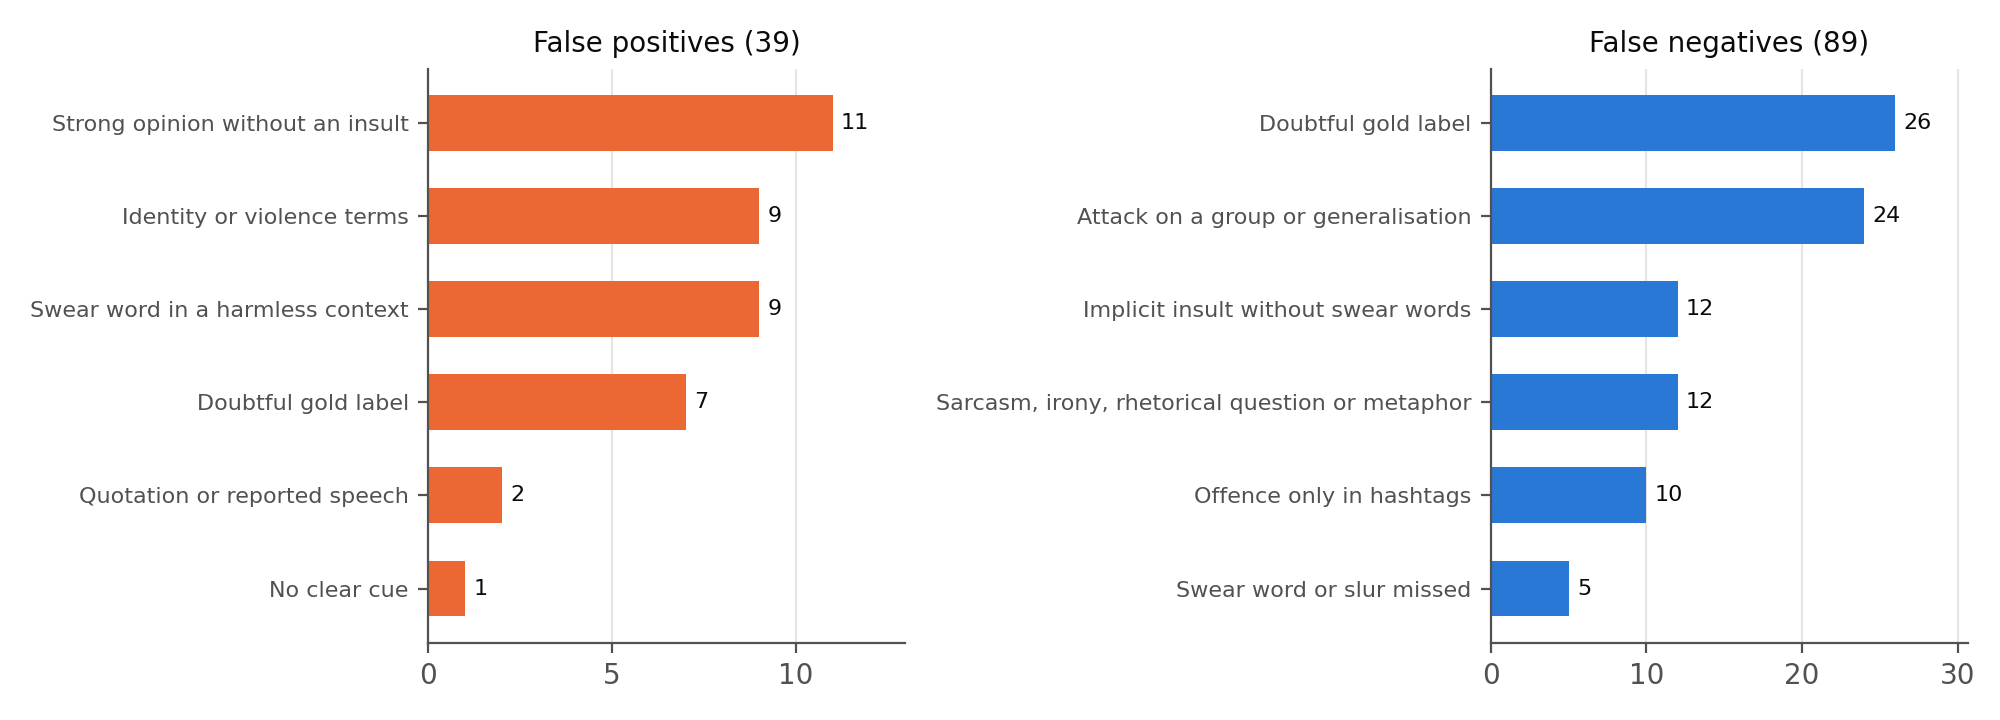

false_negative | Attack on a group or generalisation | 24 tweets
    #ChristineBlaseyFord is your #Kavanaugh accuser... #Liberals try this EVERY time... #ConfirmJudgeKavanaugh URL
    #Kids Beating #Paraplegic #Trump #Boy!  #Left Teach Their #Children Hate Violence!  #schools #teachers #Democrats #Liberals #WalkAway #Moms #Mother #NEA #teacht
false_negative | Doubtful gold label | 26 tweets
    #NoPasaran: Unity demo to oppose the far-right in #London – #antifa #Oct13 — Enough is Enough! URL
    @USER Antifa has TS level influence. It's scary.
false_negative | Implicit insult without swear words | 12 tweets
    #SerenaWilliams is so full of herself...she is just as painful to watch as to listen to...
    @USER #WalkAwayFromAllDemocrats  Michelle was there 8 years and we sure don't need any more bad advice from her now. We have a new Sheriff in Town, who's  #MAGA
false_negative | Offence only in hashtags | 10 tweets
    #SierraBurgessIsALoser  She is me when my phone dings 😂
    #Elitis

In [8]:
display(pd.read_csv('results/error_categories_summary.csv').round(1))
display(Image(filename='pics/error_categories_cross_domain.png', width=850))
ann = pd.read_csv('error_annotations_cross_domain.csv')
for (etype, cat), group in ann.groupby(['error_type', 'category']):
    print(f'{etype} | {cat} | {len(group)} tweets')
    for t in group.text.head(2):
        print('   ', t[:160])

In [9]:
os.remove('error_annotations_check.csv')
os.chdir(FINAL_DIR)